Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset.csv
Uploaded file: placement_predict_50k Dataset.csv

Dataset loaded successfully!
Dataset shape: (50000, 32)

First 5 rows:


,StudentID,Gender,City,CollegeTier,Stream,Specialisation,Hostel,HistoryOfBacklogs,SGPA_Sem1,SGPA_Sem2,...,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,CGPA_Tier,PlacementStatus,IsAnomaly,Salary Package
0,1,Male,Ahmedabad,Tier2,ECE,Networking,No,No,6.02,6.54,...,0,66.7,2.2,49.4,47.8,0,Low,0,0,0.00
1,2,Female,Mumbai,Tier2,ECE,DataScience,Yes,Yes,5.84,5.12,...,0,48.2,2.4,26.7,25.8,0,Low,0,0,0.00
2,3,Male,Kolkata,Tier2,IT,DataScience,Yes,No,4.91,5.29,...,0,73.8,2.8,67.7,41.5,0,Low,1,0,3.89
3,4,Male,Jaipur,Tier1,CS,AI,No,No,7.67,8.03,...,0,69.8,2.7,66.9,48.0,0,Mid,1,0,8.37
4,5,Male,Pune,Tier2,IT,DataScience,Yes,No,8.14,8.97,...,1,73.1,2.1,71.7,61.7,1,High,1,0,18.99



Working dataset shape: (50000, 13)

Missing values after filling:
0

X shape: (50000, 12)
y shape: (50000, 1)

Training data shape: (40000, 12)
Testing data shape: (10000, 12)

Feature scaling completed!

X_train_b shape: (40000, 13)
X_test_b shape: (10000, 13)

Batch Gradient Descent completed!
[Batch GD] Test RMSE = 4.4105


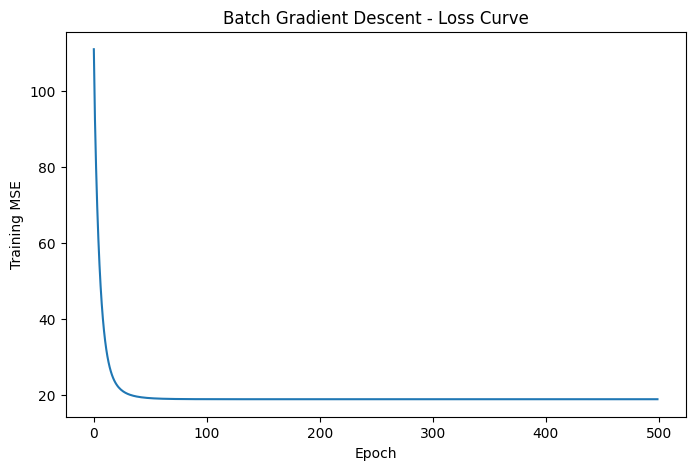

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
uploaded = files.upload()

# Automatically detect the uploaded filename
filename = list(uploaded.keys())[0]

print("Uploaded file:", filename)
df = pd.read_csv(filename)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())
FEATURES = [
    "CGPA",
    "AttendancePercent",
    "Internships",
    "Projects",
    "Workshops",
    "Certifications",
    "Publications",
    "AptitudeTestScore",
    "SoftSkillsRating",
    "CodingTestScore",
    "MockInterviewScore",
    "ExtraCurricular"
]

TARGET = "Salary Package"


data = df[FEATURES + [TARGET]].copy()

print("\nWorking dataset shape:", data.shape)

data[FEATURES] = data[FEATURES].fillna(
    data[FEATURES].median()
)

print("\nMissing values after filling:")
print(data[FEATURES].isnull().sum().sum())
X = data[FEATURES].values

y = data[TARGET].values.reshape(-1, 1)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)

X_test_s = scaler.transform(X_test)

print("\nFeature scaling completed!")
X_train_b = np.hstack([
    np.ones((X_train_s.shape[0], 1)),
    X_train_s
])

X_test_b = np.hstack([
    np.ones((X_test_s.shape[0], 1)),
    X_test_s
])

print("\nX_train_b shape:", X_train_b.shape)
print("X_test_b shape:", X_test_b.shape)
def compute_mse(X, y, theta):

    preds = X @ theta

    errors = preds - y

    return np.mean(errors ** 2)

def batch_gradient_descent(X, y, lr=0.05, n_epochs=500):

    m, n = X.shape

    # Initialize all weights to zero
    theta = np.zeros((n, 1))

    # Store loss after every epoch
    loss_history = []

    # Repeat the update 500 times
    for epoch in range(n_epochs):

        # Make predictions
        preds = X @ theta

        # Calculate prediction error
        errors = preds - y

        # Calculate gradient
        gradient = (2 / m) * (X.T @ errors)

        # Update weights
        theta -= lr * gradient

        # Store current MSE
        loss_history.append(
            compute_mse(X, y, theta)
        )

    return theta, loss_history
theta_gd, loss_history_gd = batch_gradient_descent(
    X_train_b,
    y_train,
    lr=0.05,
    n_epochs=500
)

print("\nBatch Gradient Descent completed!")

rmse_gd = np.sqrt(
    compute_mse(
        X_test_b,
        y_test,
        theta_gd
    )
)

print(
    f"[Batch GD] Test RMSE = {rmse_gd:.4f}"
)


plt.figure(figsize=(8, 5))

plt.plot(
    loss_history_gd
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")

plt.title(
    "Batch Gradient Descent - Loss Curve"
)

plt.show()
